In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from skimage.feature import peak_local_max
from tensorflow import keras

MODEL_PATH = "best_PN_UNet_focal_all_grouped.keras"
FITS_PATH = "NGC253_4channel.fits"
NORM_PATH = "PN_UNet_normalization.npz"
CATALOG_PATH = "PN_CAT.csv"
ORIGINAL_FITS_PATH = "/Users/golta/Desktop/Uni/Thesis/ADP.2025-07-06T07_52_11.876.fits"

TILE_SIZE = 64
STRIDE = 32
BATCH_SIZE = 32
PEAK_THRESHOLD = 0.40
MIN_DISTANCE = 3
MATCH_TOLERANCE = 1.0

LINE_NAMES = ["Hbeta", "OIII5007", "Halpha", "NII6584"]
SNR_COL = "OIII_SNR"
FWHM_COL = "FWHM"
M5007_COL = "m5007"
OIII_BKG_COL = "OIII_BKG"
HA_BKG_COL = "HA_BKG"

norm = np.load(NORM_PATH)
CHANNEL_MEANS = norm["channel_means"]
CHANNEL_STDS = norm["channel_stds"]
FLUX_SCALE = float(norm["flux_scale"])

print("FLUX_SCALE:", FLUX_SCALE)
print("CHANNEL_MEANS:", CHANNEL_MEANS)
print("CHANNEL_STDS:", CHANNEL_STDS)

model = keras.models.load_model(MODEL_PATH, compile=False)
print("Model input shape :", model.input_shape)
print("Model output shape:", model.output_shape)

FLUX_SCALE: 1e+18
CHANNEL_MEANS: [ 6.55170556  1.28012028 30.54480726  8.59103849]
CHANNEL_STDS: [ 500.50843468    5.39762349 2723.75963779  543.9265711 ]
Model input shape : (None, 64, 64, 4)
Model output shape: (None, 64, 64, 1)


In [25]:
with fits.open(FITS_PATH) as hdul:
    data = hdul[0].data

data = np.squeeze(np.asarray(data, dtype=np.float32))
print("Original FITS shape:", data.shape)

if data.ndim != 3:
    raise ValueError(f"Expected a 3D FITS array, got shape {data.shape}")

if data.shape[-1] == 4:
    image = data
elif data.shape[0] == 4:
    image = np.moveaxis(data, 0, -1)
else:
    raise ValueError(f"Could not find the 4-channel axis. FITS shape is {data.shape}")

print("Image shape used by network:", image.shape)
assert image.shape[-1] == 4

print("Expected channel order:")
for i, name in enumerate(LINE_NAMES):
    print(i, name)

Original FITS shape: (1733, 6080, 4)
Image shape used by network: (1733, 6080, 4)
Expected channel order:
0 Hbeta
1 OIII5007
2 Halpha
3 NII6584


In [26]:
valid_mask = np.all(np.isfinite(image), axis=-1)

image_scaled = image.astype(np.float64) * FLUX_SCALE
for c in range(4):
    bad = ~np.isfinite(image_scaled[..., c])
    image_scaled[..., c][bad] = CHANNEL_MEANS[c]

image_norm = (image_scaled - CHANNEL_MEANS[None, None, :]) / CHANNEL_STDS[None, None, :]

print("\nNormalized image statistics:")
for c, name in enumerate(LINE_NAMES):
    values = image_norm[..., c]
    print(
        f"{name:10s}: mean={np.mean(values):8.3f}, std={np.std(values):8.3f}, "
        f"min={np.min(values):8.3f}, max={np.max(values):8.3f}")


Normalized image statistics:
Hbeta     : mean=   0.003, std=  23.339, min=  -0.013, max=72889.953
OIII5007  : mean=   2.931, std=8655.458, min=  -0.237, max=28048685.073
Halpha    : mean=  -0.007, std=   0.154, min=  -0.011, max= 498.159
NII6584   : mean=  -0.008, std=   0.032, min=  -0.016, max=  57.032


In [27]:
def get_start_positions(length, tile_size, stride):
    if length <= tile_size:
        return [0]

    positions = list(range(0, length - tile_size + 1, stride))
    final_position = length - tile_size
    if positions[-1] != final_position:
        positions.append(final_position)
    return positions


def predict_full_image(model, image, tile_size=64, stride=32, batch_size=32):
    height, width, channels = image.shape
    assert channels == 4

    pad_y = max(0, tile_size - height)
    pad_x = max(0, tile_size - width)
    if pad_y > 0 or pad_x > 0:
        image_padded = np.pad(image, ((0, pad_y), (0, pad_x), (0, 0)), mode="edge")
    else:
        image_padded = image

    padded_height, padded_width, _ = image_padded.shape
    y_positions = get_start_positions(padded_height, tile_size, stride)
    x_positions = get_start_positions(padded_width, tile_size, stride)
    coordinates = [(y, x) for y in y_positions for x in x_positions]
    print("Number of tiles:", len(coordinates))

    prediction_sum = np.zeros((padded_height, padded_width), dtype=np.float32)
    weight_sum = np.zeros((padded_height, padded_width), dtype=np.float32)

    w = np.hanning(tile_size).astype(np.float32)
    weight = 0.1 + 0.9 * np.outer(w, w)

    for start in range(0, len(coordinates), batch_size):
        batch_coords = coordinates[start:start + batch_size]
        batch = np.stack([
            image_padded[y:y + tile_size, x:x + tile_size, :]
            for y, x in batch_coords
        ])
        batch_predictions = model.predict(batch, verbose=0)[..., 0]

        for (y, x), pred in zip(batch_coords, batch_predictions):
            prediction_sum[y:y + tile_size, x:x + tile_size] += pred * weight
            weight_sum[y:y + tile_size, x:x + tile_size] += weight

    full_prediction = prediction_sum / np.maximum(weight_sum, 1e-12)
    return full_prediction[:height, :width]

In [28]:
pn_heatmap = predict_full_image(model, image_norm, tile_size=TILE_SIZE, stride=STRIDE, batch_size=BATCH_SIZE)
pn_heatmap[~valid_mask] = 0.0

print("Final heatmap shape:", pn_heatmap.shape)
print("Prediction range:", pn_heatmap.min(), pn_heatmap.max())

Number of tiles: 10206
Final heatmap shape: (1733, 6080)
Prediction range: 0.0 1.0


In [29]:
def find_pn_centers(heatmap, threshold=0.3, min_distance=3):
    coords = peak_local_max(
        heatmap, min_distance=min_distance, threshold_abs=threshold, exclude_border=False)
    if len(coords) == 0:
        return np.empty((0, 3), dtype=np.float32)

    y, x = coords[:, 0], coords[:, 1]
    scores = heatmap[y, x]
    order = np.argsort(scores)[::-1]
    return np.column_stack([x[order], y[order], scores[order]])


detections = find_pn_centers(pn_heatmap, threshold=PEAK_THRESHOLD, min_distance=MIN_DISTANCE)

print("Number of PN candidates:", len(detections))
print("\n[x, y, score]")
for detection in detections:
    print(detection)

Number of PN candidates: 1122

[x, y, score]
[5.117e+03 1.060e+02 1.000e+00]
[1.633e+03 1.120e+02 1.000e+00]
[2.100e+01 1.282e+03 1.000e+00]
[4.94800000e+03 1.07000000e+02 9.99957323e-01]
[3.78800000e+03 6.89000000e+02 9.98753071e-01]
[2.56400000e+03 3.30000000e+02 9.43556368e-01]
[8.9500000e+02 1.1860000e+03 8.4549427e-01]
[4.76500000e+03 1.58000000e+03 8.42500329e-01]
[2.46400000e+03 8.53000000e+02 8.38145196e-01]
[9.01000000e+02 1.13000000e+03 8.00267935e-01]
[5.87000000e+02 1.55400000e+03 7.90593743e-01]
[3.48400000e+03 9.41000000e+02 7.87994683e-01]
[2.58800000e+03 7.59000000e+02 7.69100606e-01]
[6.60000000e+01 1.27700000e+03 7.56373703e-01]
[2.99300000e+03 4.99000000e+02 7.51923561e-01]
[3.28100000e+03 1.09600000e+03 7.26116955e-01]
[3.34500000e+03 2.17000000e+02 7.22838879e-01]
[3.39900000e+03 1.00300000e+03 7.20547497e-01]
[2.44500000e+03 1.09900000e+03 7.16861308e-01]
[2.32000000e+03 9.66000000e+02 7.11637497e-01]
[2.19600000e+03 8.58000000e+02 7.03322291e-01]
[2.92800000e+03 

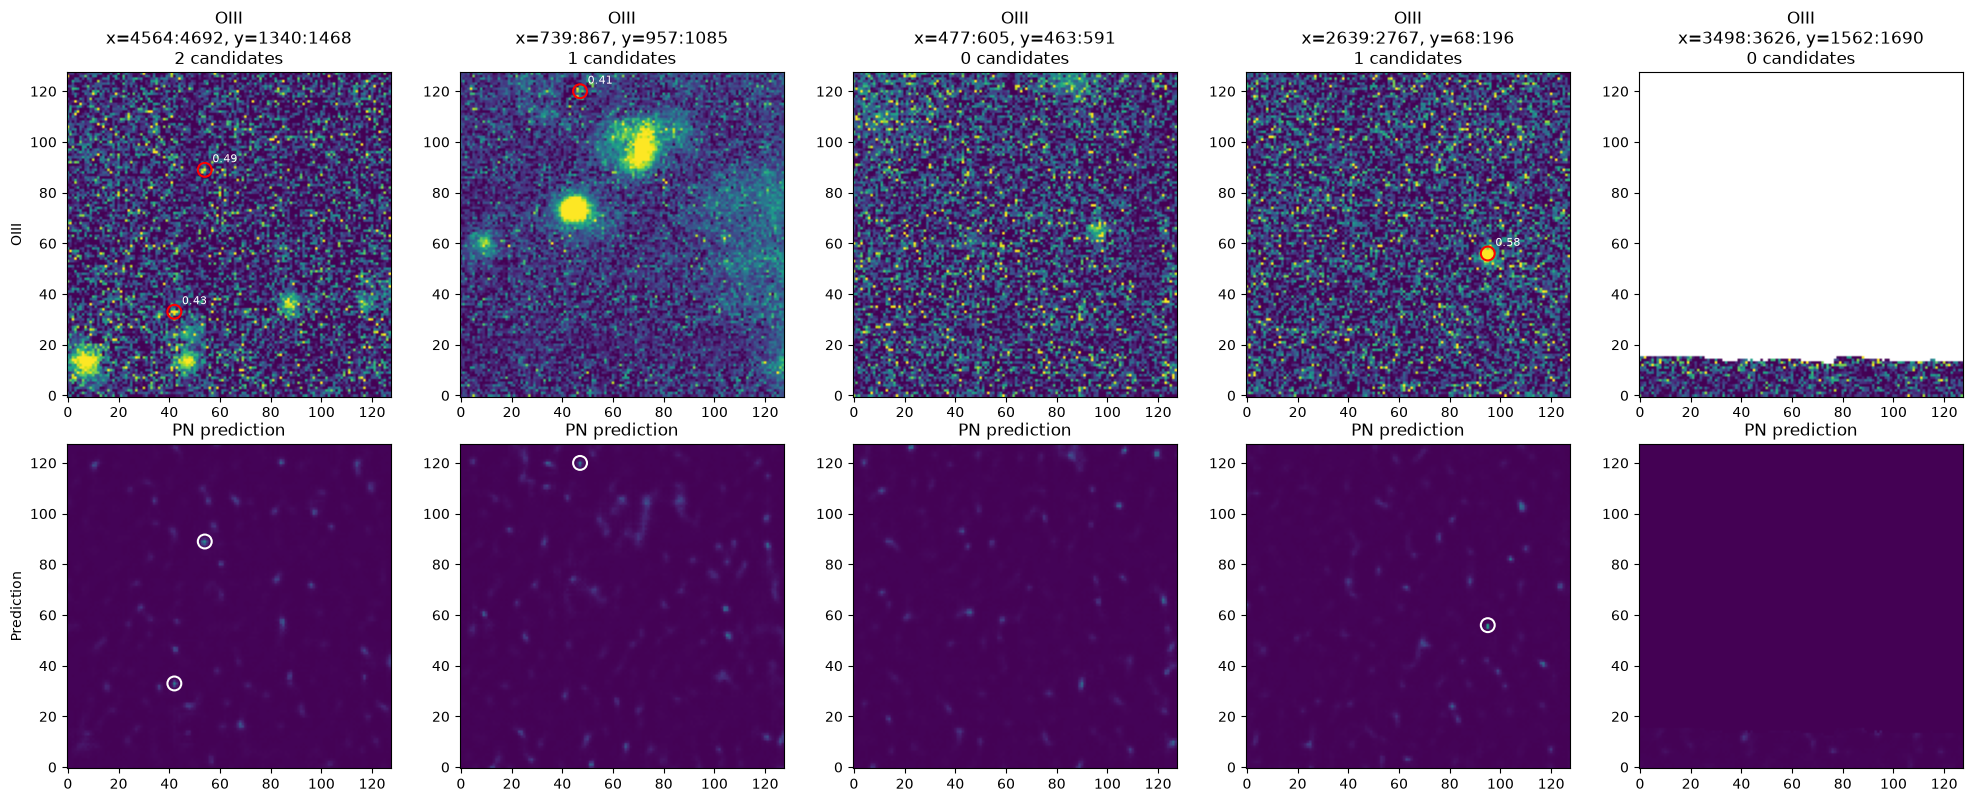

In [30]:
def plot_random_cutouts(image, pn_heatmap, detections, n_cutouts=6, cutout_size=128, seed=42, threshold=0.20):
    rng = np.random.default_rng(seed)
    height, width, _ = image.shape
    oiii = image[..., 1]

    _, axes = plt.subplots(2, n_cutouts, figsize=(4 * n_cutouts, 8))
    if n_cutouts == 1:
        axes = axes[:, None]

    for i in range(n_cutouts):
        x0 = rng.integers(0, max(1, width - cutout_size))
        y0 = rng.integers(0, max(1, height - cutout_size))
        x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

        oiii_cutout = oiii[y0:y1, x0:x1]
        pred_cutout = pn_heatmap[y0:y1, x0:x1]

        inside = (
            (detections[:, 0] >= x0) & (detections[:, 0] < x1)
            & (detections[:, 1] >= y0) & (detections[:, 1] < y1)
            & (detections[:, 2] >= threshold))
        det = detections[inside]

        if len(det) > 0:
            local_x = det[:, 0] - x0
            local_y = det[:, 1] - y0

        finite = oiii_cutout[np.isfinite(oiii_cutout)]
        if len(finite) > 0:
            vmin, vmax = np.percentile(finite, 10), np.percentile(finite, 99)
        else:
            vmin, vmax = 0, 1

        ax = axes[0, i]
        ax.imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
        if len(det) > 0:
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="red", s=100, linewidths=1.5)
            for x, y, score in zip(local_x, local_y, det[:, 2]):
                ax.text(x + 3, y + 3, f"{score:.2f}", color="white", fontsize=8)
        ax.set_title(f"OIII\nx={x0}:{x1}, y={y0}:{y1}\n{len(det)} candidates")

        ax = axes[1, i]
        ax.imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
        if len(det) > 0:
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="white", s=100, linewidths=1.5)
        ax.set_title("PN prediction")

    axes[0, 0].set_ylabel("OIII")
    axes[1, 0].set_ylabel("Prediction")
    plt.tight_layout()
    plt.show()


plot_random_cutouts(
    image=image, pn_heatmap=pn_heatmap, detections=detections,
    n_cutouts=5, cutout_size=128, seed=100)

In [31]:
pn_catalog = pd.read_csv(CATALOG_PATH)
print(pn_catalog.head())
print("Number of catalogue PNe:", len(pn_catalog))

with fits.open(ORIGINAL_FITS_PATH) as hdul:
    wcs = WCS(hdul["OIII5006_FLUX"].header).celestial

ra = pn_catalog["RAdeg"].to_numpy()
dec = pn_catalog["DEdeg"].to_numpy()
catalog_x, catalog_y = wcs.world_to_pixel_values(ra, dec)
pn_catalog["x"] = catalog_x
pn_catalog["y"] = catalog_y

print(pn_catalog[["ID", "RAdeg", "DEdeg", "x", "y"]].head())

height, width, _ = image.shape
inside_image = (
    np.isfinite(pn_catalog["x"]) & np.isfinite(pn_catalog["y"])
    & (pn_catalog["x"] >= 0) & (pn_catalog["x"] < width)
    & (pn_catalog["y"] >= 0) & (pn_catalog["y"] < height))

catalog_in_image = pn_catalog[inside_image].copy()
print(f"Catalogue PNe inside image: {len(catalog_in_image)} / {len(pn_catalog)}")

   ID      RAdeg      DEdeg   FWHM  log_OIII_Hb  log_NII_Ha  log_SII_Ha  \
0   1  11.987615 -25.221952  0.956     1.871572    0.028113   -1.241971   
1   2  11.994759 -25.220211  0.923     1.776825   -0.548196   -1.497087   
2   3  12.021884 -25.194207  0.786     1.073425   -0.153119   -2.029765   
3   4  11.992403 -25.218152  1.080     1.436248   -0.857334   -0.846140   
4   5  11.990650 -25.220049  1.083     1.405052   -0.738616   -0.659834   

    m5007  OIII_SNR  OIII_BKG     HA_BKG  use_NII  use_SII  
0  24.724    95.148  4635.374   8483.608    False    False  
1  25.008    81.816  5043.334   8932.815    False    False  
2  24.709   132.907  3856.435  15246.028     True    False  
3  25.433    48.006  4647.829  12368.687    False    False  
4  25.789    37.488  5518.461  12392.201    False    False  
Number of catalogue PNe: 571
   ID      RAdeg      DEdeg            x           y
0   1  11.987615 -25.221952  1048.627172  768.130699
1   2  11.994759 -25.220211   938.519031  719.19

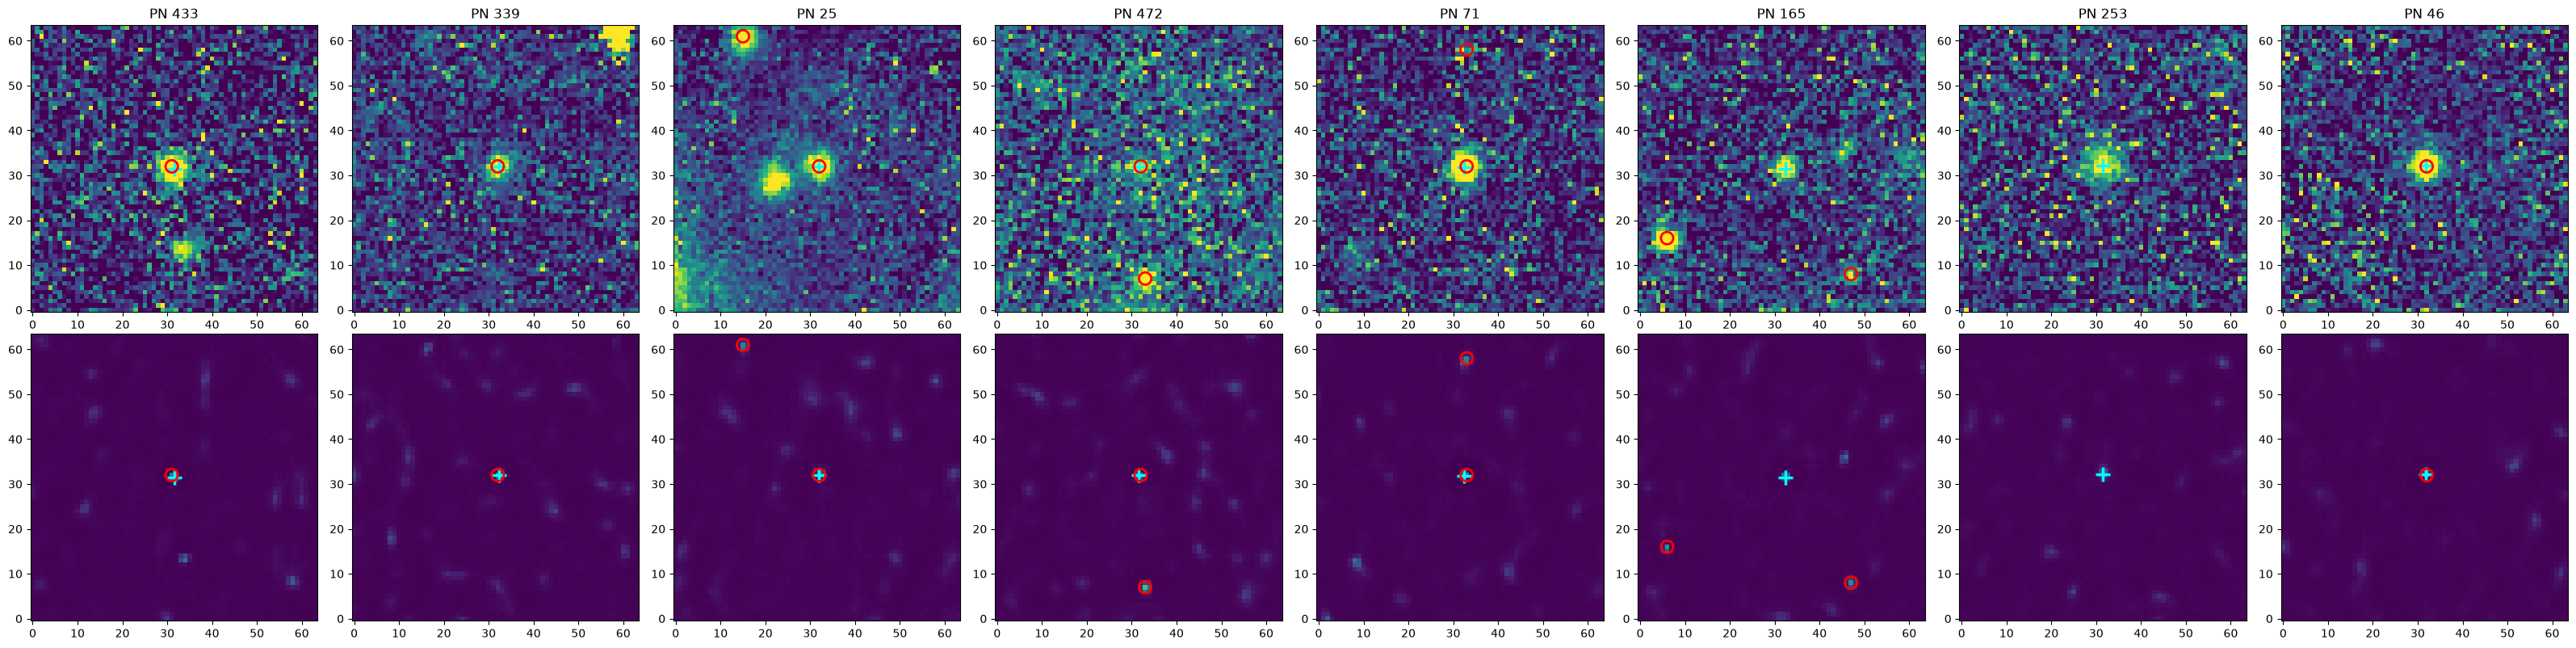

In [32]:
def plot_catalog_pn_cutouts(image, pn_heatmap, detections, catalog, n_cutouts=8, cutout_size=64, seed=42, threshold=0.20):
    rng = np.random.default_rng(seed)
    height, width, _ = image.shape
    oiii = image[..., 1]

    n = min(n_cutouts, len(catalog))
    selected_indices = rng.choice(len(catalog), size=n, replace=False)
    selected = catalog.iloc[selected_indices]
    _, axes = plt.subplots(2, n, figsize=(4 * n, 8))
    if n == 1:
        axes = axes[:, None]

    half = cutout_size // 2
    for i, (_, pn) in enumerate(selected.iterrows()):
        xc, yc = pn["x"], pn["y"]
        x0 = max(0, min(int(round(xc)) - half, width - cutout_size))
        y0 = max(0, min(int(round(yc)) - half, height - cutout_size))
        x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

        oiii_cutout = oiii[y0:y1, x0:x1]
        pred_cutout = pn_heatmap[y0:y1, x0:x1]
        cat_x, cat_y = xc - x0, yc - y0

        inside = (
            (detections[:, 0] >= x0) & (detections[:, 0] < x1)
            & (detections[:, 1] >= y0) & (detections[:, 1] < y1)
            & (detections[:, 2] >= threshold))
        det = detections[inside]
        model_x, model_y = det[:, 0] - x0, det[:, 1] - y0

        finite = oiii_cutout[np.isfinite(oiii_cutout)]
        if len(finite):
            vmin, vmax = np.percentile(finite, 8), np.percentile(finite, 99)
        else:
            vmin, vmax = 0, 1

        axes[0, i].imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
        axes[0, i].scatter(cat_x, cat_y, marker="+", s=180, linewidths=2.5, c="cyan")
        if len(det):
            axes[0, i].scatter(model_x, model_y, facecolors="none", edgecolors="red", s=120, linewidths=2)
        axes[0, i].set_title(f"PN {int(pn['ID'])}")

        axes[1, i].imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
        axes[1, i].scatter(cat_x, cat_y, marker="+", s=180, linewidths=2.5, c="cyan")
        if len(det):
            axes[1, i].scatter(model_x, model_y, facecolors="none", edgecolors="red", s=120, linewidths=2)

    plt.tight_layout()
    plt.show()


plot_catalog_pn_cutouts(
    image=image, pn_heatmap=pn_heatmap, detections=detections,
    catalog=catalog_in_image, n_cutouts=8, cutout_size=64, seed=100)

In [33]:
def match_catalog_to_detections(catalog, detections, tolerance=1.0):
    catalog = catalog.copy()
    cat_xy = catalog[["x", "y"]].to_numpy(dtype=np.float32)

    matched = np.zeros(len(catalog), dtype=bool)
    matched_detection_x = np.full(len(catalog), np.nan)
    matched_detection_y = np.full(len(catalog), np.nan)
    matched_detection_score = np.full(len(catalog), np.nan)
    matched_distance = np.full(len(catalog), np.nan)

    for det_x, det_y, det_score in detections:
        distances = np.sqrt((cat_xy[:, 0] - det_x)**2 + (cat_xy[:, 1] - det_y)**2)
        distances[matched] = np.inf
        nearest_index = np.argmin(distances)
        nearest_distance = distances[nearest_index]

        if nearest_distance <= tolerance:
            matched[nearest_index] = True
            matched_detection_x[nearest_index] = det_x
            matched_detection_y[nearest_index] = det_y
            matched_detection_score[nearest_index] = det_score
            matched_distance[nearest_index] = nearest_distance

    catalog["detected_by_model"] = matched
    catalog["matched_x"] = matched_detection_x
    catalog["matched_y"] = matched_detection_y
    catalog["matched_score"] = matched_detection_score
    catalog["match_distance_pix"] = matched_distance

    matched_catalog = catalog[catalog["detected_by_model"]].copy()
    missed_catalog = catalog[~catalog["detected_by_model"]].copy()
    return matched_catalog, missed_catalog


matched_catalog, missed_catalog = match_catalog_to_detections(catalog=catalog_in_image, detections=detections, tolerance=MATCH_TOLERANCE)

print("========================================")
print("CATALOGUE PN RECOVERY")
print("========================================")
print(f"Catalogue PNe inside image : {len(catalog_in_image)}")
print(f"Catalogue PNe detected     : {len(matched_catalog)}")
print(f"Catalogue PNe NOT detected : {len(missed_catalog)}")

completeness = len(matched_catalog) / len(catalog_in_image)
print(f"Catalogue completeness     : {completeness:.3f} ({100 * completeness:.1f}%)")
print("\nMissed catalogue PNe:")
display(missed_catalog[["ID", "RAdeg", "DEdeg", "x", "y"]].head(20))


CATALOGUE PN RECOVERY
Catalogue PNe inside image : 571
Catalogue PNe detected     : 359
Catalogue PNe NOT detected : 212
Catalogue completeness     : 0.629 (62.9%)

Missed catalogue PNe:


,ID,RAdeg,DEdeg,x,y
1,2,11.994759,-25.220211,938.519031,719.198444
3,4,11.992403,-25.218152,944.981903,772.147353
4,5,11.990650,-25.220049,988.645826,763.612216
6,7,11.984182,-25.225646,1133.912851,751.703038
7,8,11.981760,-25.224133,1147.402788,797.692968
8,9,11.982123,-25.228810,1195.833625,728.580977
9,10,11.982070,-25.226832,1174.085247,756.777834
11,12,11.995105,-25.228126,1023.897314,605.000000
12,13,12.003594,-25.213527,750.990950,722.000000
13,14,12.009609,-25.210389,639.346743,704.162956


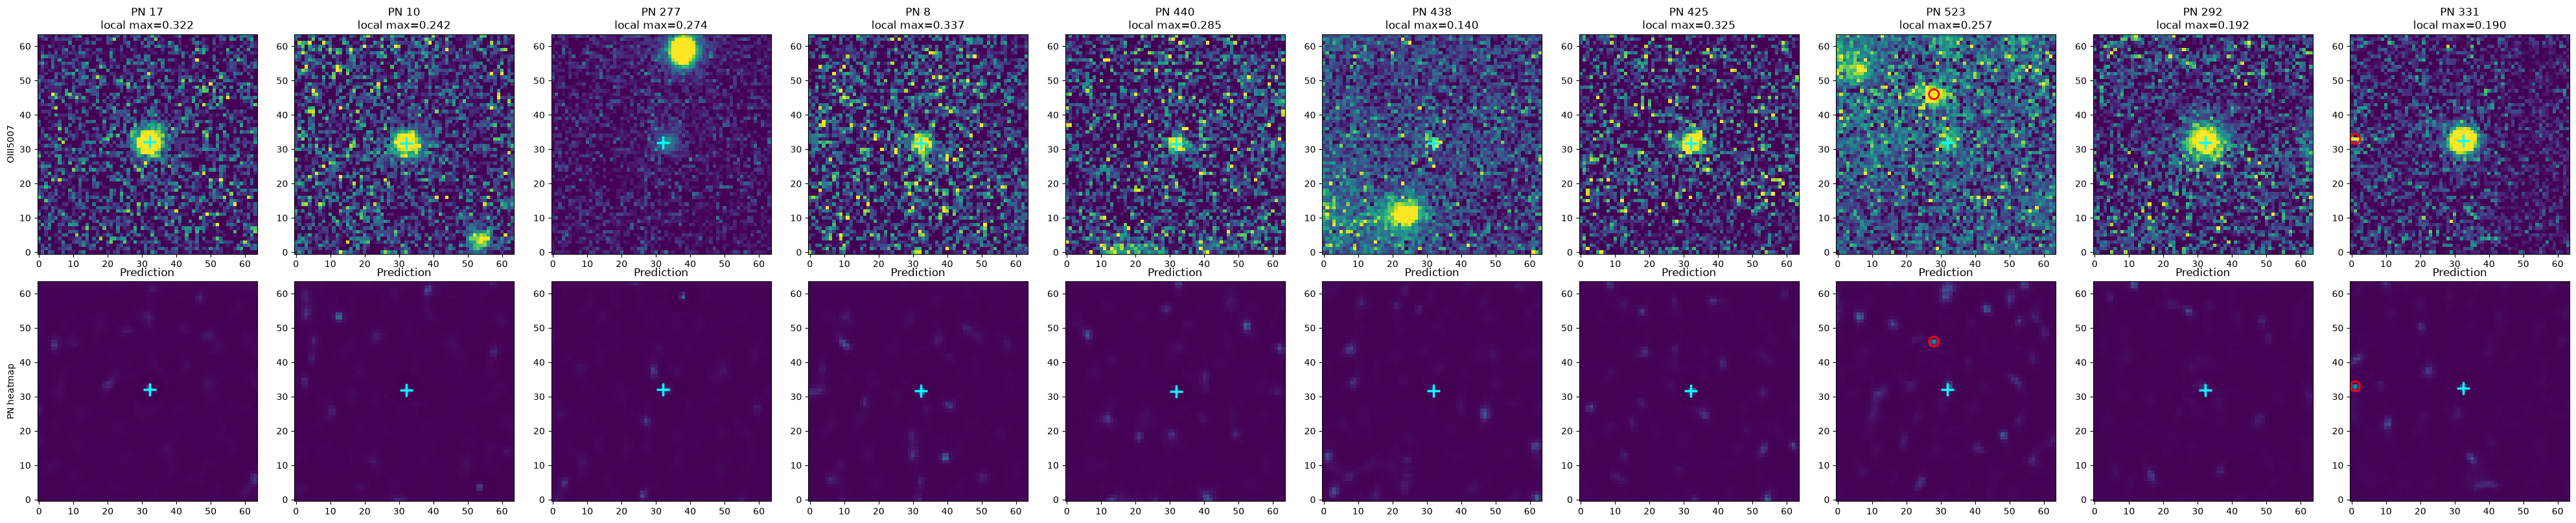

In [34]:
def plot_random_missed_pne(image, pn_heatmap, detections, missed_catalog, n_samples=10, cutout_size=64, seed=42):
    if len(missed_catalog) == 0:
        print("No missed catalogue PNe!")
        return

    rng = np.random.default_rng(seed)
    height, width, _ = image.shape
    oiii = image[..., 1]

    n = min(n_samples, len(missed_catalog))
    selected_indices = rng.choice(len(missed_catalog), size=n, replace=False)
    selected = missed_catalog.iloc[selected_indices]
    _, axes = plt.subplots(2, n, figsize=(4 * n, 8))
    if n == 1:
        axes = axes[:, None]

    half = cutout_size // 2
    for i, (_, pn) in enumerate(selected.iterrows()):
        xc, yc = float(pn["x"]), float(pn["y"])
        x0 = max(0, min(int(round(xc)) - half, width - cutout_size))
        y0 = max(0, min(int(round(yc)) - half, height - cutout_size))
        x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

        oiii_cutout = oiii[y0:y1, x0:x1]
        pred_cutout = pn_heatmap[y0:y1, x0:x1]
        cat_x, cat_y = xc - x0, yc - y0

        inside = (
            (detections[:, 0] >= x0) & (detections[:, 0] < x1)
            & (detections[:, 1] >= y0) & (detections[:, 1] < y1))
        det = detections[inside]
        if len(det) > 0:
            local_det_x = det[:, 0] - x0
            local_det_y = det[:, 1] - y0

        search_radius = 3
        cx, cy = int(round(xc)), int(round(yc))
        sx0, sx1 = max(0, cx - search_radius), min(width, cx + search_radius + 1)
        sy0, sy1 = max(0, cy - search_radius), min(height, cy + search_radius + 1)
        local_max_score = np.max(pn_heatmap[sy0:sy1, sx0:sx1])

        finite = oiii_cutout[np.isfinite(oiii_cutout)]
        if len(finite) > 0:
            vmin, vmax = np.percentile(finite, 8), np.percentile(finite, 99)
        else:
            vmin, vmax = 0, 1

        ax = axes[0, i]
        ax.imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
        ax.scatter(cat_x, cat_y, marker="+", s=200, linewidths=2.5, c="cyan")
        if len(det) > 0:
            ax.scatter(local_det_x, local_det_y, facecolors="none", edgecolors="red", s=120, linewidths=2)
        ax.set_title(f"PN {pn['ID']}\nlocal max={local_max_score:.3f}")

        ax = axes[1, i]
        ax.imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
        ax.scatter(cat_x, cat_y, marker="+", s=200, linewidths=2.5, c="cyan")
        if len(det) > 0:
            ax.scatter(local_det_x, local_det_y, facecolors="none", edgecolors="red", s=120, linewidths=2)
        ax.set_title("Prediction")

    axes[0, 0].set_ylabel("OIII5007")
    axes[1, 0].set_ylabel("PN heatmap")
    plt.tight_layout()
    plt.show()


plot_random_missed_pne(
    image=image, pn_heatmap=pn_heatmap, detections=detections,
    missed_catalog=missed_catalog, n_samples=10, cutout_size=64, seed=40)

In [35]:
evaluated_catalog = pd.concat([matched_catalog, missed_catalog], ignore_index=True)
if "ID" in evaluated_catalog.columns:
    evaluated_catalog = evaluated_catalog.sort_values("ID").reset_index(drop=True)

print(evaluated_catalog.columns.tolist())
print("Detected:", evaluated_catalog["detected_by_model"].sum())
print("Missed:", (~evaluated_catalog["detected_by_model"]).sum())

['ID', 'RAdeg', 'DEdeg', 'FWHM', 'log_OIII_Hb', 'log_NII_Ha', 'log_SII_Ha', 'm5007', 'OIII_SNR', 'OIII_BKG', 'HA_BKG', 'use_NII', 'use_SII', 'x', 'y', 'detected_by_model', 'matched_x', 'matched_y', 'matched_score', 'match_distance_pix']
Detected: 359
Missed: 212


OIII S/N statistics
Detected: N=359, median=72.90, mean=80.99
Missed:   N=212, median=48.51, mean=58.27


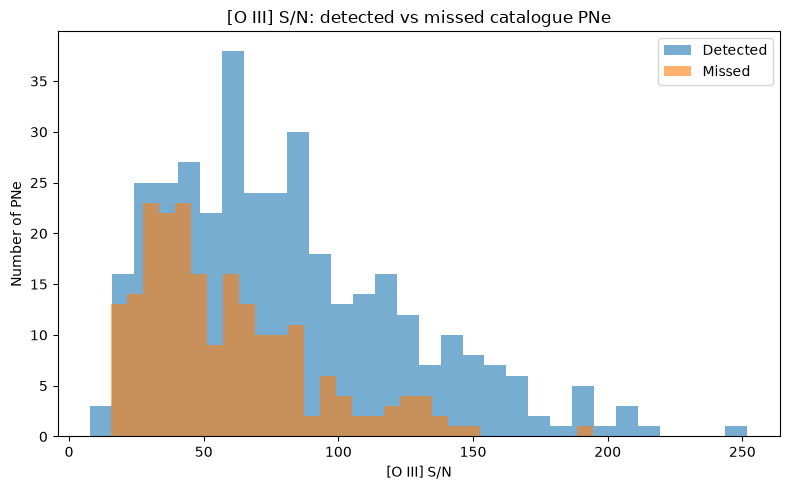

In [36]:
snr_data = evaluated_catalog[np.isfinite(evaluated_catalog[SNR_COL])].copy()
detected_snr = snr_data.loc[snr_data["detected_by_model"], SNR_COL]
missed_snr = snr_data.loc[~snr_data["detected_by_model"], SNR_COL]

print("OIII S/N statistics")
print("====================")
print(f"Detected: N={len(detected_snr)}, median={np.median(detected_snr):.2f}, mean={np.mean(detected_snr):.2f}")
print(f"Missed:   N={len(missed_snr)}, median={np.median(missed_snr):.2f}, mean={np.mean(missed_snr):.2f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_snr, bins=30, alpha=0.6, density=False, label="Detected")
plt.hist(missed_snr, bins=30, alpha=0.6, density=False, label="Missed")
plt.xlabel("[O III] S/N")
plt.ylabel("Number of PNe")
plt.title("[O III] S/N: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

,snr_bin,snr_median,snr_min,snr_max,n_total,n_detected,completeness
0,"(7.941999999999999, 29.588]",23.7235,7.943,29.580,72,36,0.500000
1,"(29.588, 39.928]",34.3230,29.612,39.766,71,33,0.464789
2,"(39.928, 50.03]",45.4180,40.090,49.946,71,37,0.521127
3,"(50.03, 63.627]",59.0285,50.058,63.627,72,43,0.597222
4,"(63.627, 78.328]",71.2990,63.653,78.257,71,47,0.661972
5,"(78.328, 93.237]",84.1190,78.540,93.231,71,48,0.676056
6,"(93.237, 124.521]",108.9750,93.243,124.476,71,54,0.760563
7,"(124.521, 251.791]",148.1835,124.536,251.791,72,61,0.847222


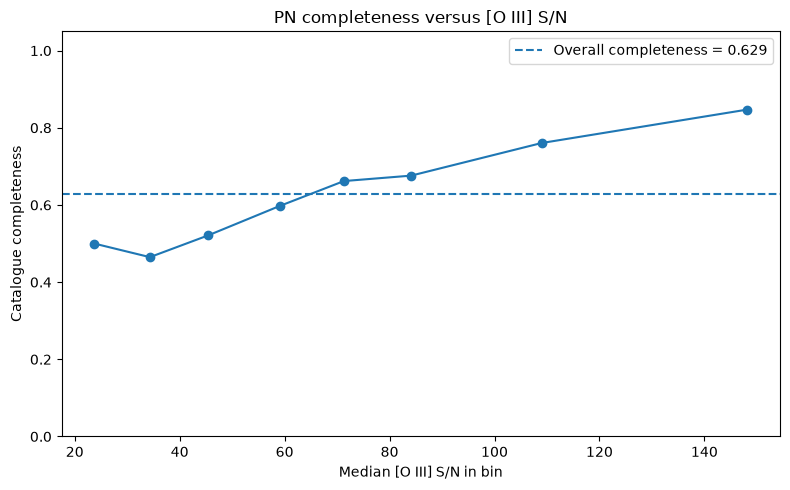

In [37]:
snr_data["snr_bin"] = pd.qcut(snr_data[SNR_COL], q=8, duplicates="drop")
snr_completeness = (
    snr_data.groupby("snr_bin", observed=True)
    .agg(
        snr_median=(SNR_COL, "median"),
        snr_min=(SNR_COL, "min"),
        snr_max=(SNR_COL, "max"),
        n_total=("detected_by_model", "size"),
        n_detected=("detected_by_model", "sum")).reset_index())
snr_completeness["completeness"] = snr_completeness["n_detected"] / snr_completeness["n_total"]
display(snr_completeness)

plt.figure(figsize=(8, 5))
plt.plot(snr_completeness["snr_median"], snr_completeness["completeness"], marker="o")
plt.axhline(completeness, linestyle="--", label=f"Overall completeness = {completeness:.3f}")
plt.xlabel("Median [O III] S/N in bin")
plt.ylabel("Catalogue completeness")
plt.ylim(0, 1.05)
plt.title("PN completeness versus [O III] S/N")
plt.legend()
plt.tight_layout()
plt.show()

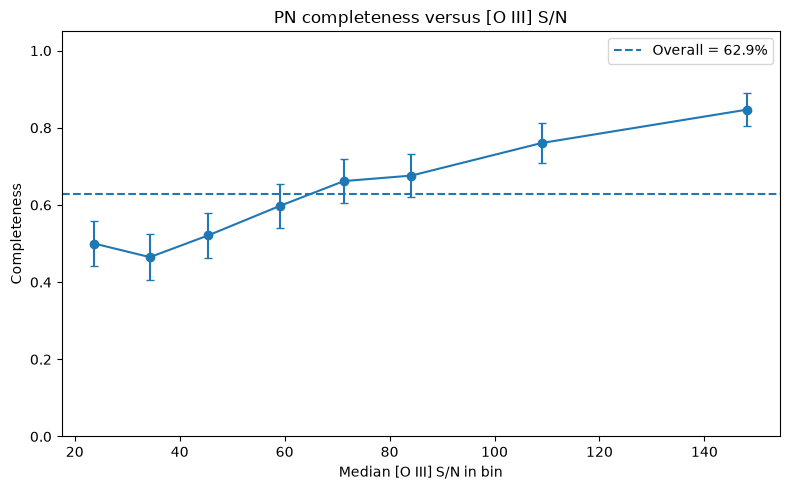

In [38]:
snr_completeness["error"] = np.sqrt(snr_completeness["completeness"] * 
                                    (1 - snr_completeness["completeness"]) / snr_completeness["n_total"])

plt.figure(figsize=(8, 5))
plt.errorbar(
    snr_completeness["snr_median"], snr_completeness["completeness"],
    yerr=snr_completeness["error"], marker="o", capsize=3)
plt.axhline(completeness, linestyle="--", label=f"Overall = {100 * completeness:.1f}%")
plt.xlabel("Median [O III] S/N in bin")
plt.ylabel("Completeness")
plt.ylim(0, 1.05)
plt.title("PN completeness versus [O III] S/N")
plt.legend()
plt.tight_layout()
plt.show()

FWHM statistics
Detected: N=359, median=0.723, mean=0.744
Missed:   N=212, median=0.839, mean=0.879


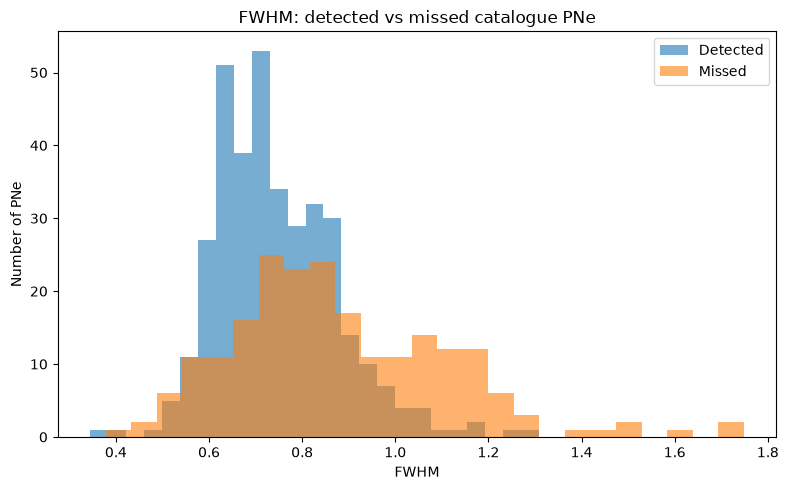

In [39]:
fwhm_data = evaluated_catalog[np.isfinite(evaluated_catalog[FWHM_COL])].copy()
detected_fwhm = fwhm_data.loc[fwhm_data["detected_by_model"], FWHM_COL]
missed_fwhm = fwhm_data.loc[~fwhm_data["detected_by_model"], FWHM_COL]

print("FWHM statistics")
print("===============")
print(f"Detected: N={len(detected_fwhm)}, median={np.median(detected_fwhm):.3f}, mean={np.mean(detected_fwhm):.3f}")
print(f"Missed:   N={len(missed_fwhm)}, median={np.median(missed_fwhm):.3f}, mean={np.mean(missed_fwhm):.3f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_fwhm, bins=25, alpha=0.6, density=False, label="Detected")
plt.hist(missed_fwhm, bins=25, alpha=0.6, density=False, label="Missed")
plt.xlabel("FWHM")
plt.ylabel("Number of PNe")
plt.title("FWHM: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

,fwhm_bin,fwhm_median,fwhm_min,fwhm_max,n_total,n_detected,completeness,error
0,"(0.344, 0.616]",0.577,0.345,0.616,75,53,0.706667,0.052572
1,"(0.616, 0.662]",0.639,0.617,0.661,68,55,0.808824,0.047686
2,"(0.662, 0.709]",0.692,0.663,0.709,73,61,0.835616,0.043378
3,"(0.709, 0.76]",0.734,0.710,0.760,70,45,0.642857,0.057270
4,"(0.76, 0.821]",0.792,0.761,0.821,72,47,0.652778,0.056107
5,"(0.821, 0.876]",0.845,0.822,0.875,70,46,0.657143,0.056733
6,"(0.876, 1.012]",0.924,0.876,1.010,71,39,0.549296,0.059050
7,"(1.012, 1.748]",1.119,1.012,1.748,72,13,0.180556,0.045331


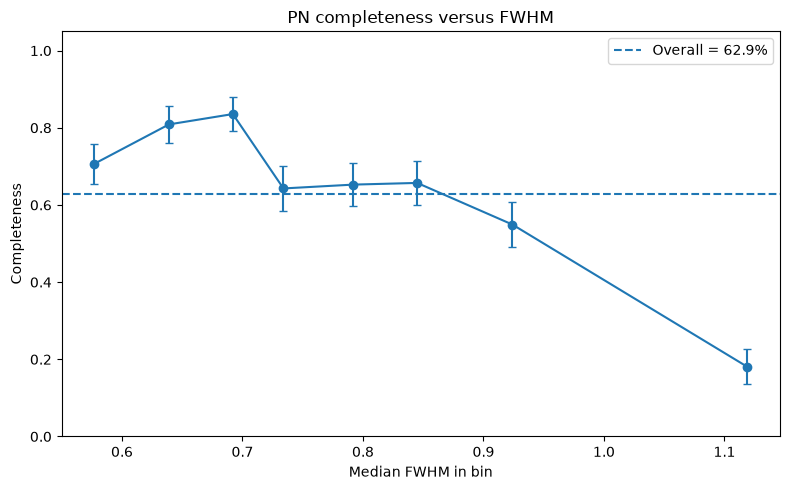

In [40]:
fwhm_data["fwhm_bin"] = pd.qcut(fwhm_data[FWHM_COL], q=8, duplicates="drop")
fwhm_completeness = (
    fwhm_data.groupby("fwhm_bin", observed=True)
    .agg(
        fwhm_median=(FWHM_COL, "median"),
        fwhm_min=(FWHM_COL, "min"),
        fwhm_max=(FWHM_COL, "max"),
        n_total=("detected_by_model", "size"),
        n_detected=("detected_by_model", "sum")).reset_index())
fwhm_completeness["completeness"] = fwhm_completeness["n_detected"] / fwhm_completeness["n_total"]
fwhm_completeness["error"] = np.sqrt(
    fwhm_completeness["completeness"] * (1 - fwhm_completeness["completeness"])
    / fwhm_completeness["n_total"]
)
display(fwhm_completeness)

plt.figure(figsize=(8, 5))
plt.errorbar(
    fwhm_completeness["fwhm_median"], fwhm_completeness["completeness"],
    yerr=fwhm_completeness["error"], marker="o", capsize=3
)
plt.axhline(completeness, linestyle="--", label=f"Overall = {100 * completeness:.1f}%")
plt.xlabel("Median FWHM in bin")
plt.ylabel("Completeness")
plt.ylim(0, 1.05)
plt.title("PN completeness versus FWHM")
plt.legend()
plt.tight_layout()
plt.show()


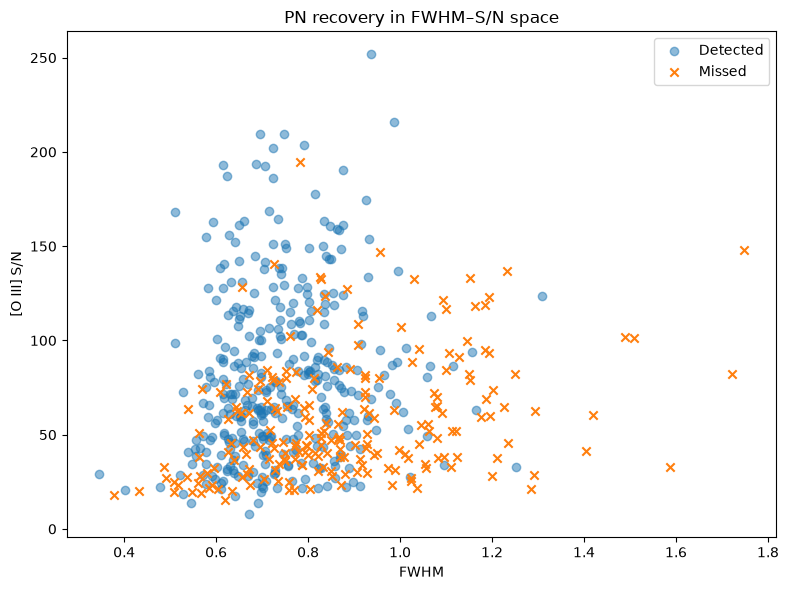

In [41]:
combined = evaluated_catalog[
    np.isfinite(evaluated_catalog[SNR_COL]) & np.isfinite(evaluated_catalog[FWHM_COL])
].copy()
det = combined["detected_by_model"]

plt.figure(figsize=(8, 6))
plt.scatter(combined.loc[det, FWHM_COL], combined.loc[det, SNR_COL], alpha=0.5, label="Detected")
plt.scatter(combined.loc[~det, FWHM_COL], combined.loc[~det, SNR_COL], marker="x", label="Missed")
plt.xlabel("FWHM")
plt.ylabel("[O III] S/N")
plt.title("PN recovery in FWHM–S/N space")
plt.legend()
plt.tight_layout()
plt.show()


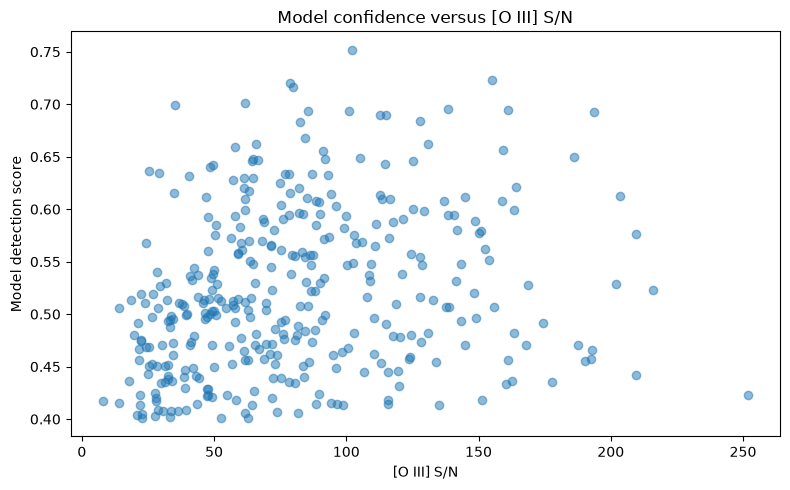

In [42]:
plt.figure(figsize=(8, 5))
plt.scatter(matched_catalog[SNR_COL], matched_catalog["matched_score"], alpha=0.5)
plt.xlabel("[O III] S/N")
plt.ylabel("Model detection score")
plt.title("Model confidence versus [O III] S/N")
plt.tight_layout()
plt.show()


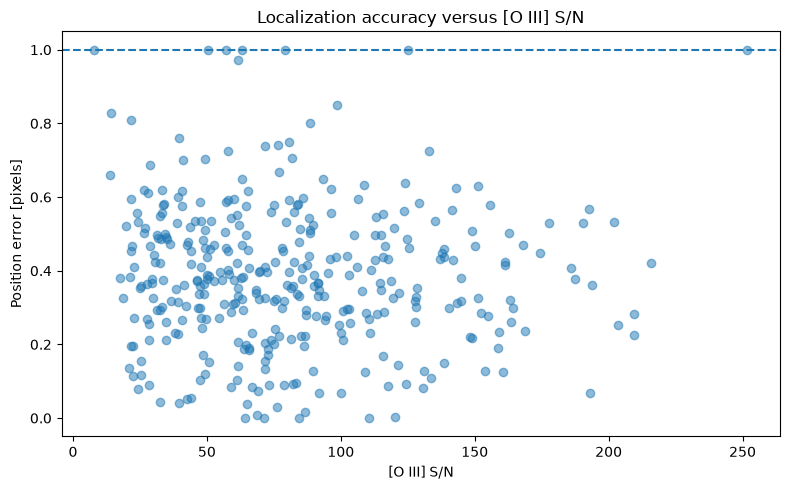

In [43]:
plt.figure(figsize=(8, 5))
plt.scatter(matched_catalog[SNR_COL], matched_catalog["match_distance_pix"], alpha=0.5)
plt.axhline(MATCH_TOLERANCE, linestyle="--")
plt.xlabel("[O III] S/N")
plt.ylabel("Position error [pixels]")
plt.title("Localization accuracy versus [O III] S/N")
plt.tight_layout()
plt.show()

OIII M5007 statistics
Detected: N=359, median=25.18, mean=25.23
Missed:   N=212, median=25.60, mean=25.61


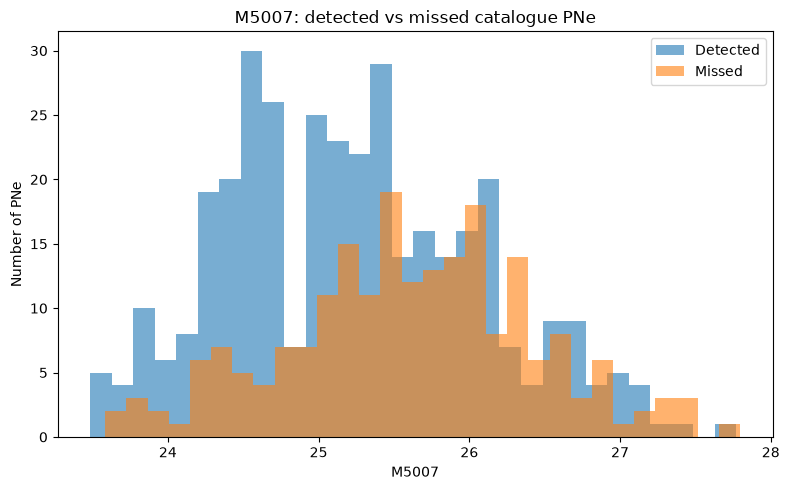

In [44]:
m5007_data = evaluated_catalog[np.isfinite(evaluated_catalog[M5007_COL])].copy()
detected_m5007 = m5007_data.loc[m5007_data["detected_by_model"], M5007_COL]
missed_m5007 = m5007_data.loc[~m5007_data["detected_by_model"], M5007_COL]

print("OIII M5007 statistics")
print("====================")
print(f"Detected: N={len(detected_m5007)}, median={np.median(detected_m5007):.2f}, mean={np.mean(detected_m5007):.2f}")
print(f"Missed:   N={len(missed_m5007)}, median={np.median(missed_m5007):.2f}, mean={np.mean(missed_m5007):.2f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_m5007, bins=30, alpha=0.6, density=False, label="Detected")
plt.hist(missed_m5007, bins=30, alpha=0.6, density=False, label="Missed")
plt.xlabel("M5007")
plt.ylabel("Number of PNe")
plt.title("M5007: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

OIII BKG statistics
Detected: N=359, median=3837.14, mean=4714.90
Missed:   N=212, median=4612.31, mean=5421.77
HA BKG statistics
Detected: N=359, median=17520.92, mean=27612.40
Missed:   N=212, median=14290.49, mean=22773.84


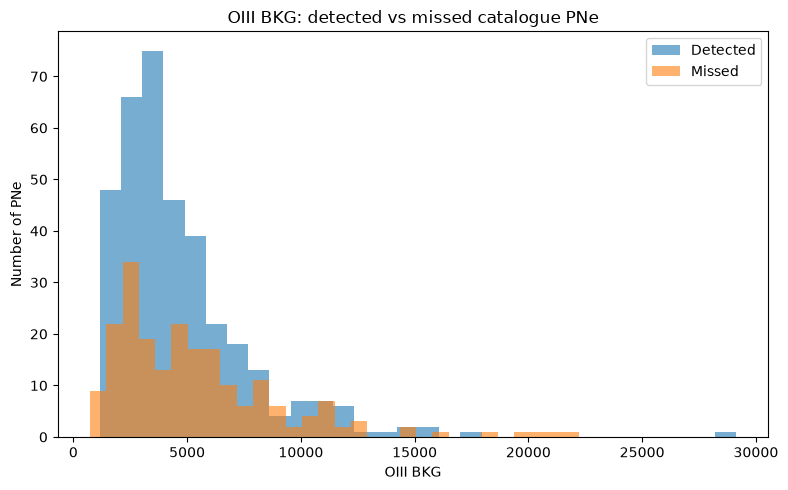

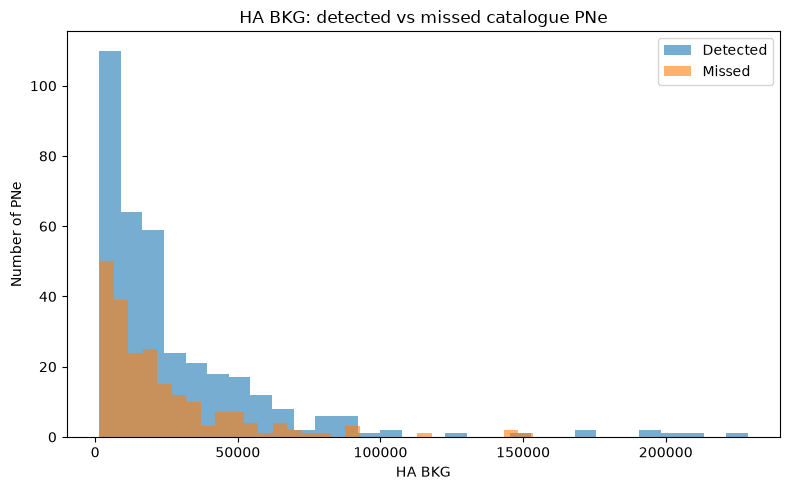

In [45]:
oiii_bkg_data = evaluated_catalog[np.isfinite(evaluated_catalog[OIII_BKG_COL])].copy()
detected_oiii_bkg = oiii_bkg_data.loc[oiii_bkg_data["detected_by_model"], OIII_BKG_COL]
missed_oiii_bkg = oiii_bkg_data.loc[~m5007_data["detected_by_model"], OIII_BKG_COL]

ha_bkg_data = evaluated_catalog[np.isfinite(evaluated_catalog[HA_BKG_COL])].copy()
detected_ha_bkg = ha_bkg_data.loc[ha_bkg_data["detected_by_model"], HA_BKG_COL]
missed_ha_bkg = ha_bkg_data.loc[~m5007_data["detected_by_model"], HA_BKG_COL]

print("OIII BKG statistics")
print("====================")
print(f"Detected: N={len(detected_oiii_bkg)}, median={np.median(detected_oiii_bkg):.2f}, mean={np.mean(detected_oiii_bkg):.2f}")
print(f"Missed:   N={len(missed_oiii_bkg)}, median={np.median(missed_oiii_bkg):.2f}, mean={np.mean(missed_oiii_bkg):.2f}")

print("HA BKG statistics")
print("====================")
print(f"Detected: N={len(detected_ha_bkg)}, median={np.median(detected_ha_bkg):.2f}, mean={np.mean(detected_ha_bkg):.2f}")
print(f"Missed:   N={len(missed_ha_bkg)}, median={np.median(missed_ha_bkg):.2f}, mean={np.mean(missed_ha_bkg):.2f}")

plt.figure(figsize=(8, 5))
plt.hist(detected_oiii_bkg, bins=30, alpha=0.6, density=False, label="Detected")
plt.hist(missed_oiii_bkg, bins=30, alpha=0.6, density=False, label="Missed")
plt.xlabel("OIII BKG")
plt.ylabel("Number of PNe")
plt.title("OIII BKG: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(detected_ha_bkg, bins=30, alpha=0.6, density=False, label="Detected")
plt.hist(missed_ha_bkg, bins=30, alpha=0.6, density=False, label="Missed")
plt.xlabel("HA BKG")
plt.ylabel("Number of PNe")
plt.title("HA BKG: detected vs missed catalogue PNe")
plt.legend()
plt.tight_layout()
plt.show()

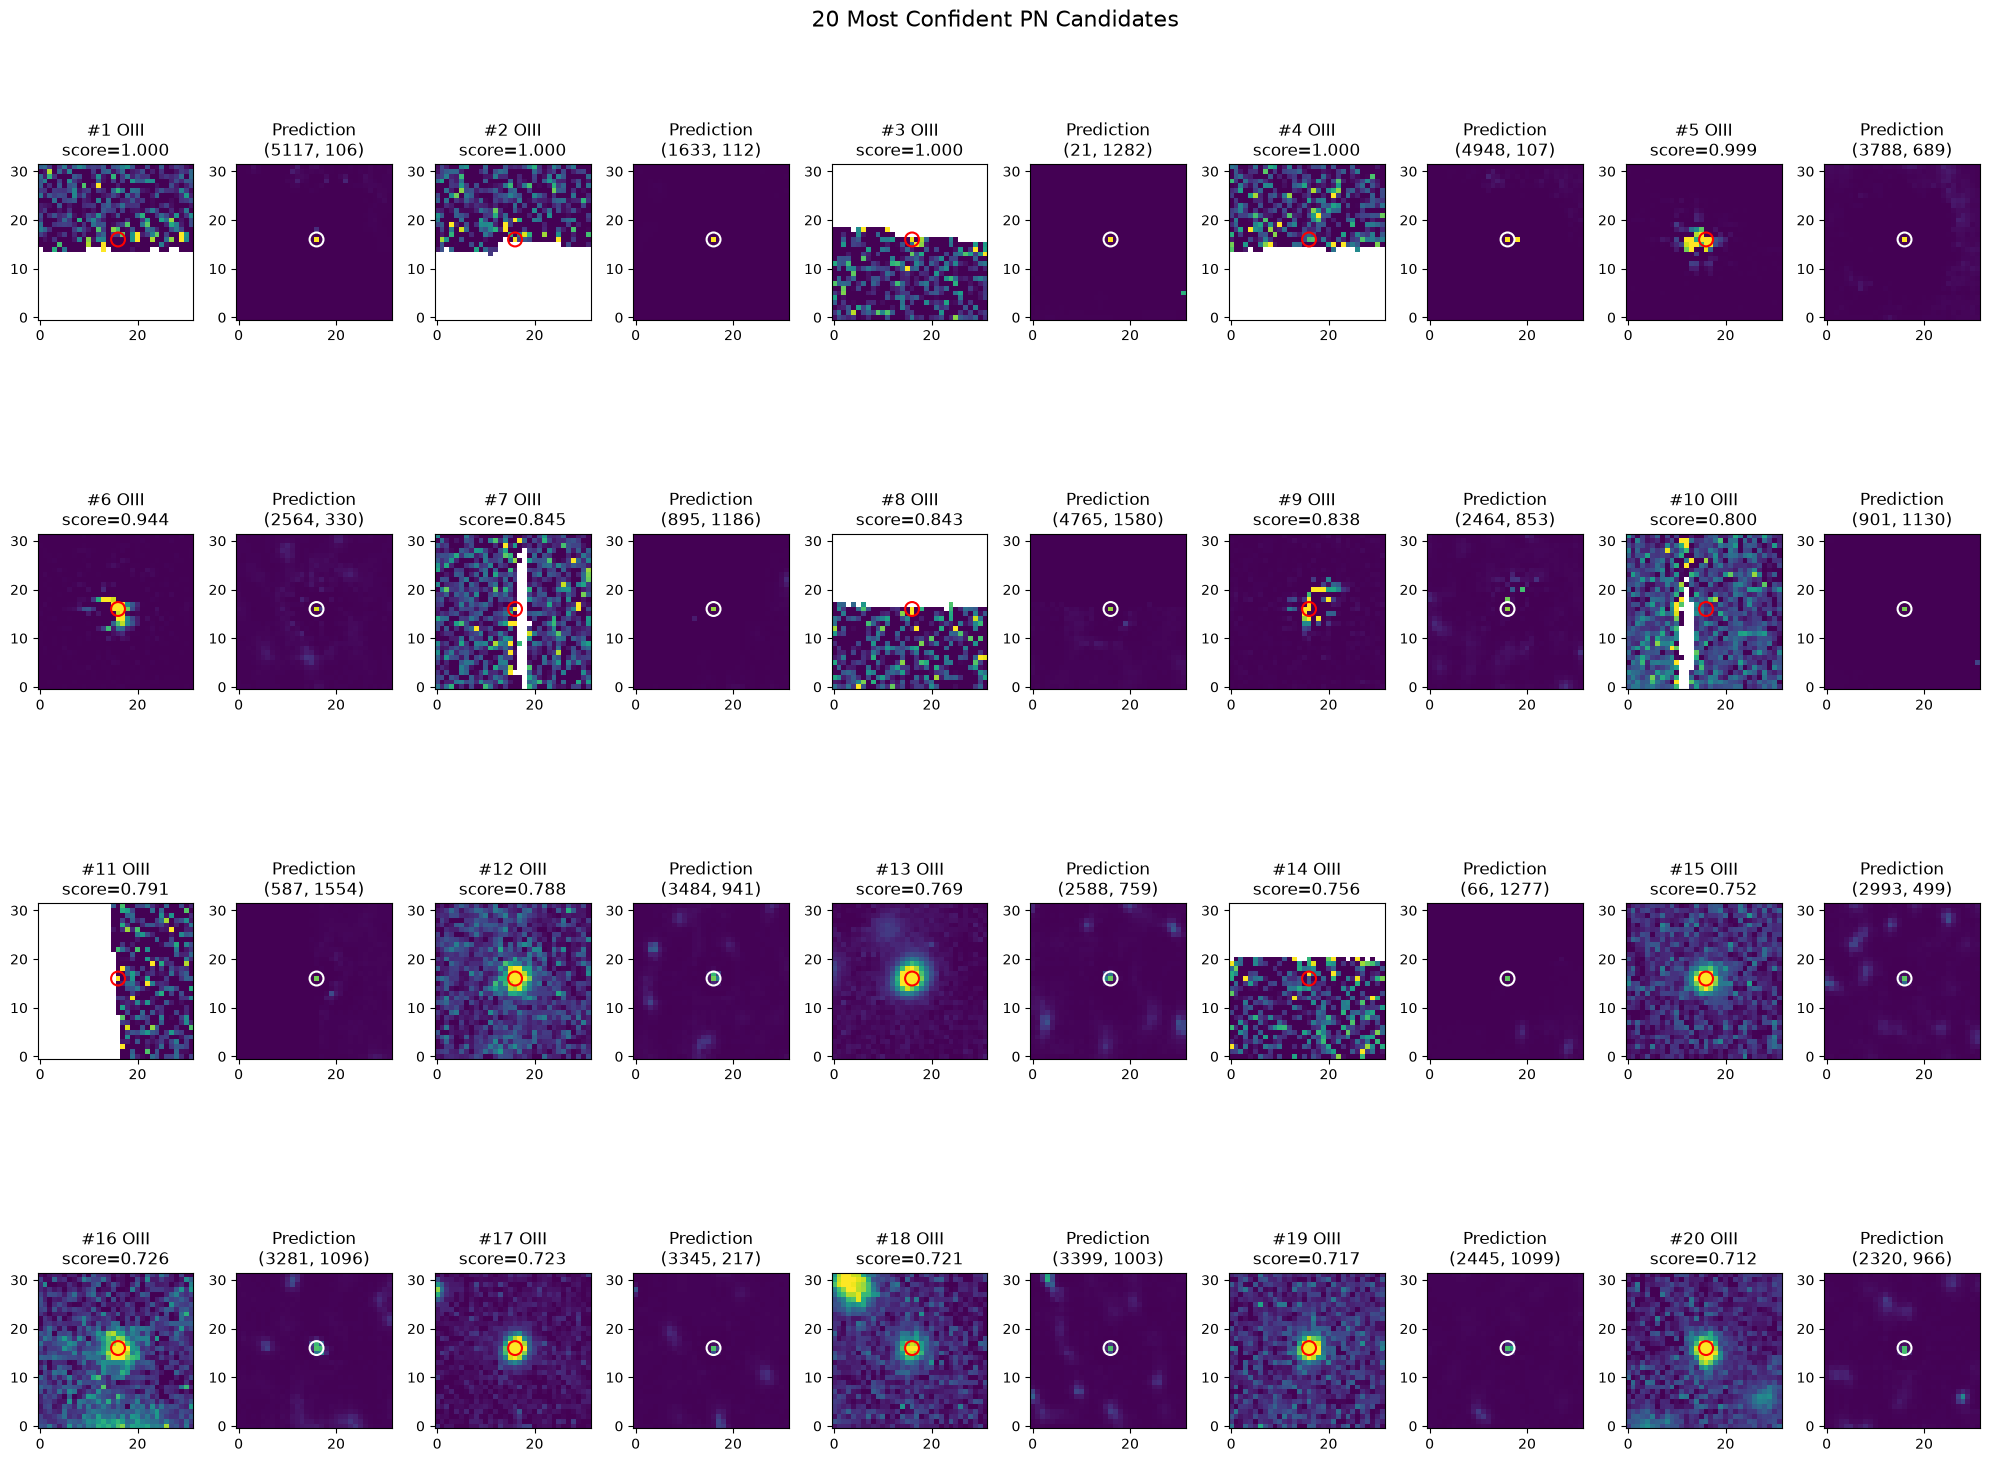

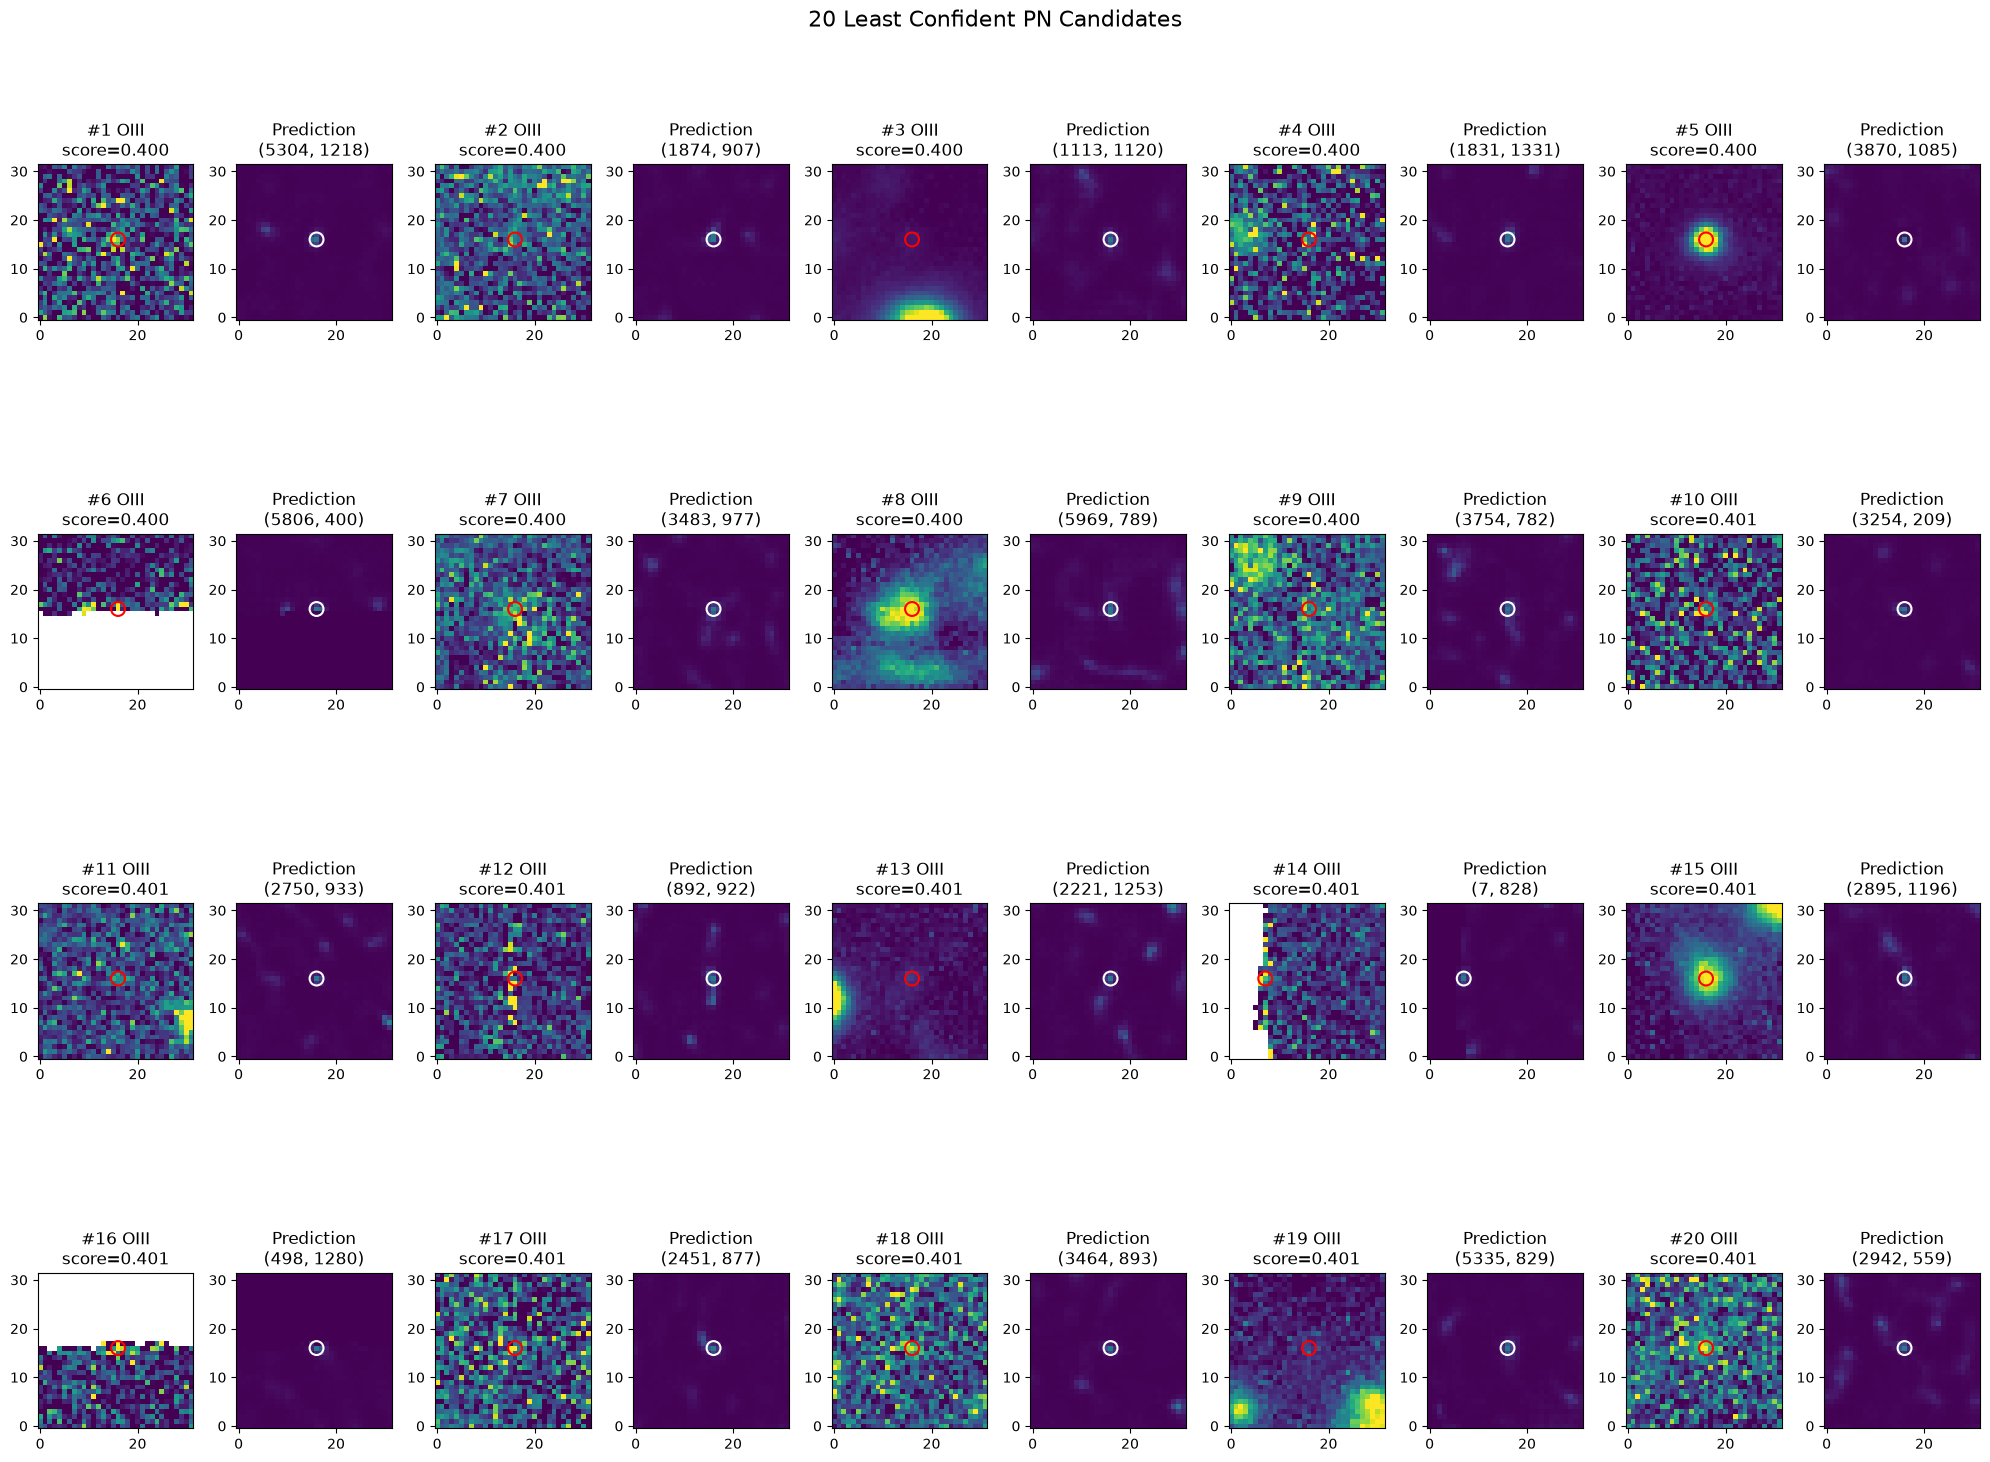

In [46]:
def plot_confidence_cutouts(image, pn_heatmap, detections, n_sources=20, cutout_size=32):
    oiii = image[..., 1]
    height, width = pn_heatmap.shape
    half = cutout_size // 2

    def plot_group(selected, title):
        n = len(selected)
        n_rows = int(np.ceil(n / 5))
        fig, axes = plt.subplots(n_rows, 10, figsize=(20, 4 * n_rows))
        axes = np.atleast_2d(axes)

        for i, (x, y, score) in enumerate(selected):
            x, y = int(round(x)), int(round(y))
            x0 = max(0, min(x - half, width - cutout_size))
            y0 = max(0, min(y - half, height - cutout_size))
            x1, y1 = min(x0 + cutout_size, width), min(y0 + cutout_size, height)

            oiii_cutout = oiii[y0:y1, x0:x1]
            pred_cutout = pn_heatmap[y0:y1, x0:x1]
            local_x, local_y = x - x0, y - y0

            finite = oiii_cutout[np.isfinite(oiii_cutout)]
            vmin, vmax = np.percentile(finite, [8, 99]) if len(finite) else (0, 1)

            row, col = i // 5, (i % 5) * 2

            ax = axes[row, col]
            ax.imshow(oiii_cutout, origin="lower", vmin=vmin, vmax=vmax)
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="red", s=100, linewidths=1.5)
            ax.set_title(f"#{i + 1} OIII\nscore={score:.3f}")

            ax = axes[row, col + 1]
            ax.imshow(pred_cutout, origin="lower", vmin=0, vmax=1)
            ax.scatter(local_x, local_y, facecolors="none", edgecolors="white", s=100, linewidths=1.5)
            ax.set_title(f"Prediction\n({x}, {y})")

        for ax in axes.flat[2 * n:]:
            ax.axis("off")

        fig.suptitle(title, fontsize=16)
        plt.tight_layout()
        plt.show()

    n = min(n_sources, len(detections))
    plot_group(detections[:n], f"{n} Most Confident PN Candidates")
    plot_group(detections[-n:][::-1], f"{n} Least Confident PN Candidates")


plot_confidence_cutouts(
    image=image,
    pn_heatmap=pn_heatmap,
    detections=detections,
    n_sources=20,
    cutout_size=32
)